# Where Does NILM Accuracy Go? — Leakage-Aware NILM Benchmark + BEACON (REFIT)

**What this notebook does**
1. Downloads REFIT (cleaned, 20 houses, 8 s, CC BY 4.0) and regularises it to an 8 s grid (houses without target-appliance activity are excluded automatically).
2. Trains models under protocols ordered from most to least leakage: **P0** random windows → **P1** chronological split within each house → **P2** leave-one-house-out (LOHO, with a separate validation house).
3. Measures further leakage channels: **L3** sub-meter-sum ("denoised") aggregate (retrained under P2), **L4** test-house target statistics, **L5** active-window curation, **L6** test-set checkpoint selection.
4. Compares trivial baselines, **seq2point**, **HI-S2P** and the proposed **BEACON** (Background-swap, Edge-aware, Aggregate-CONstrained, ON-gated network), with ablations.
5. Statistics: paired per-house Wilcoxon signed-rank test (P2) and bootstrap intervals across houses, both only when enough houses are available.
6. Knowledge extraction: baseline-shift sensitivity, occlusion saliency, house-identity probe.
7. (Optional) Part B: cross-dataset test REFIT → UK-DALE.

**How to run:** Runtime → Change runtime type → **GPU (T4 or better)**, then Run all.
Start with `QUICK = True` to check that everything runs, then set `False` for the full results.
Results are saved after every run (the notebook resumes where it stopped). Set `SAVE_TO_DRIVE = True` so results survive a disconnected session; `APPLIANCES` can be used to run one appliance at a time.

⚠️ **Full results need all 20 REFIT houses**: download `CLEAN_REFIT_081116.7z` in a browser and upload it to `MyDrive/refit/` (the Zenodo mirror has only 6 houses).

## 0. Setup

In [1]:
import os, sys, time, json, math, random, gc, subprocess, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

IN_COLAB = 'google.colab' in sys.modules
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch', torch.__version__)
if DEVICE.type == 'cpu':
    print('⚠️ No GPU found — Runtime > Change runtime type > GPU (CPU will be very slow)')

Colab: True | device: cuda | torch 2.11.0+cu130


## 1. Configuration

In [2]:
QUICK = True            # True = quick system check / False = full run for the paper
APPLIANCES = ['kettle'] if QUICK else ['kettle', 'microwave', 'fridge', 'dishwasher', 'washingmachine']
MAIN_MODELS = ['seq2point', 'hi_s2p', 'beacon']
ABLATION_MODELS = ['beacon_noSwap', 'beacon_noGate', 'beacon_noLocal', 'hi_s2p_noGRL']   # run under P2 (LOHO) only
MODELS     = MAIN_MODELS if QUICK else MAIN_MODELS + ABLATION_MODELS
SEEDS      = [0] if QUICK else [0, 1, 2]
N_LOHO_TEST_HOUSES = 2 if QUICK else None   # None = every house is a test house (full LOHO)
RUN_L3_RETRAIN = True   # L3 retrains MAIN_MODELS only (≈2× the P2 time)
EXCLUDE_EMPTY_HOUSES = True   # drop houses with (almost) no target activity, e.g. a wrong channel
MIN_ON_FRAC = 1e-4            # minimum on-time fraction (0.01%)

WINDOW            = 599                 # seq2point window (≈80 min at 8 s)
SAMPLE_PERIOD     = 8                   # seconds (REFIT)
EPOCHS            = 5 if QUICK else 20
SAMPLES_PER_EPOCH = 100_000 if QUICK else 600_000
BATCH             = 1024
LR                = 1e-3
PATIENCE          = 5                   # early stopping on validation (never on test)
MAX_ROWS_PER_HOUSE = 1_500_000 if QUICK else None   # ≈140 days per house in QUICK
EVAL_MAX_POINTS   = 200_000 if QUICK else 1_000_000 # max test points per house (systematic stride)

DATA_DIR = '/content/refit' if IN_COLAB else os.path.abspath('refit')
OUT_DIR  = '/content/results' if IN_COLAB else os.path.abspath('results')
SAVE_TO_DRIVE = False                   # True = mount Google Drive and save results to MyDrive/nilm_results
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

# REFIT appliance -> (houses, ApplianceN channel in CLEAN_HouseN.csv) + standard parameters
# ⚠️ confirm channels against REFIT_Readme.txt before using results
REFIT_APPLIANCES = {
    'kettle':         dict(houses=[2,3,4,5,6,7,8,9,12,13,19,20], channels=[8,9,9,8,7,9,9,7,6,9,5,9],
                           on_threshold=2000, max_power=3998),
    'microwave':      dict(houses=[4,10,12,17,19],               channels=[8,8,3,7,4],
                           on_threshold=200,  max_power=3969),
    'fridge':         dict(houses=[2,5,9,12,15],                 channels=[1,1,1,1,1],
                           on_threshold=50,   max_power=3323),
    'dishwasher':     dict(houses=[5,7,9,13,16,18,20],           channels=[4,6,4,4,6,6,5],
                           on_threshold=10,   max_power=3964),
    'washingmachine': dict(houses=[2,5,7,8,9,15,16,17,18],       channels=[2,3,5,4,3,3,5,4,5],
                           on_threshold=20,   max_power=3999),
}
AGG_CLIP = 10_000  # W

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/nilm_results'; os.makedirs(OUT_DIR, exist_ok=True)
print('APPLIANCES', APPLIANCES, '| MODELS', MODELS, '| SEEDS', SEEDS, '| OUT_DIR', OUT_DIR)

APPLIANCES ['kettle'] | MODELS ['seq2point', 'hi_s2p', 'beacon'] | SEEDS [0] | OUT_DIR /content/results


## 2. Download REFIT (cleaned)
Source: Murray et al., REFIT Electrical Load Measurements (Cleaned), University of Strathclyde, DOI 10.15129/9ab14b0e-19ac-4279-938f-27f643078cec (≈490 MB)

Search order: (1) Google Drive `MyDrive/refit/CLEAN_REFIT_081116.7z` → (2) direct download from Strathclyde → (3) Zenodo record 5063428 (6 houses only).
Strathclyde often returns HTTP 403 to Colab. **For full results**, download the `.7z` in a browser and upload it to the Drive path above.

In [3]:
REFIT_URL = 'https://pureportal.strath.ac.uk/files/62090184/CLEAN_REFIT_081116.7z'
# Fallback: download the .7z in a browser on your own machine and upload it to Google Drive at this path
DRIVE_ARCHIVE = '/content/drive/MyDrive/refit/CLEAN_REFIT_081116.7z'
MIN_ARCHIVE_BYTES = 400_000_000   # the full archive is ≈ 490 MB

def _ok_archive(path):
    return os.path.exists(path) and os.path.getsize(path) > MIN_ARCHIVE_BYTES

def _download(url, dest):
    """Try requests (browser-like User-Agent) first, then curl; always delete incomplete downloads."""
    import requests
    hdr = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                         '(KHTML, like Gecko) Chrome/124.0 Safari/537.36',
           'Accept': '*/*', 'Referer': 'https://pureportal.strath.ac.uk/'}
    try:
        with requests.get(url, headers=hdr, stream=True, timeout=60, allow_redirects=True) as r:
            print('  HTTP', r.status_code, r.headers.get('content-type'))
            r.raise_for_status()
            total = int(r.headers.get('content-length', 0)); got = 0
            with open(dest, 'wb') as f:
                for chunk in r.iter_content(chunk_size=8 << 20):
                    f.write(chunk); got += len(chunk)
                    if total: print(f'\r  {got/1e6:,.0f}/{total/1e6:,.0f} MB', end='')
            print()
    except Exception as e:
        print('  requests failed:', e)
    if not _ok_archive(dest):
        if os.path.exists(dest): os.remove(dest)
        print('  trying curl ...')
        subprocess.run(['curl', '-L', '--fail', '--retry', '3', '-A', hdr['User-Agent'],
                        '-e', hdr['Referer'], '-o', dest, url], check=False)
    if not _ok_archive(dest):
        if os.path.exists(dest): os.remove(dest)   # never leave a broken/empty file that would skip the next download
        return False
    return True

ZENODO_HOUSES = [1, 2, 3, 4, 5, 11]
ZENODO_URL = 'https://zenodo.org/records/5063428/files/CLEAN_House{h}.csv?download=1'

def ensure_refit_zenodo():
    need = sorted({h for a in APPLIANCES for h in REFIT_APPLIANCES[a]['houses']} & set(ZENODO_HOUSES))
    for h in need:
        dest = os.path.join(DATA_DIR, f'CLEAN_House{h}.csv')
        if os.path.exists(dest) and os.path.getsize(dest) > 100_000_000: continue
        print(f'  Zenodo: CLEAN_House{h}.csv')
        r = subprocess.run(['curl', '-L', '--fail', '--retry', '3', '-o', dest, ZENODO_URL.format(h=h)])
        if r.returncode != 0 and os.path.exists(dest): os.remove(dest)
    have = sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.csv'))
    print('files:', have)
    for a in APPLIANCES:
        n = len(set(REFIT_APPLIANCES[a]['houses']) & {int(f[11:-4]) for f in have})
        print(f'  {a}: {n} houses' + ('  ⚠️ not enough for LOHO (need ≥ 3)' if n < 3 else ''))

def ensure_refit():
    have = [f for f in os.listdir(DATA_DIR) if f.startswith('CLEAN_House') and f.endswith('.csv')]
    if len(have) >= 15:
        print(f'found {len(have)} files in {DATA_DIR}'); return
    arc = os.path.join(DATA_DIR, 'CLEAN_REFIT.7z')
    # accept a user-uploaded .7z in DATA_DIR or /content (any name)
    for d in [DATA_DIR, '/content']:
        if os.path.isdir(d):
            for f in os.listdir(d):
                fp = os.path.join(d, f)
                if f.endswith('.7z') and fp != arc and _ok_archive(fp):
                    print('using uploaded file:', fp); arc = fp; break
        if arc != os.path.join(DATA_DIR, 'CLEAN_REFIT.7z'): break
    if os.path.exists(arc) and not _ok_archive(arc):
        print(f'⚠️ {arc} is {os.path.getsize(arc)/1e6:.0f} MB (full file ≈ 490 MB) — the upload may be incomplete')
        os.remove(arc); print('incomplete file removed')
    if not _ok_archive(arc):
        # 1) Google Drive (if the user uploaded the archive there)
        if IN_COLAB:
            from google.colab import drive
            if not os.path.exists('/content/drive/MyDrive'): drive.mount('/content/drive')
        if _ok_archive(DRIVE_ARCHIVE):
            print('using file from Google Drive:', DRIVE_ARCHIVE); shutil.copy(DRIVE_ARCHIVE, arc)
        else:
            # 2) direct download from Strathclyde
            print('downloading REFIT ...')
            if not _download(REFIT_URL, arc):
                # 3) fallback: Zenodo (6 houses only) — enough for QUICK, not for the paper
                print('\n⚠️ Strathclyde blocked the download → using Zenodo instead (houses 1, 2, 3, 4, 5, 11 only)')
                print(f'   For full results: download {REFIT_URL} in a browser and upload it to {DRIVE_ARCHIVE}\n')
                ensure_refit_zenodo(); return
    if subprocess.run(['which', '7z'], capture_output=True).returncode != 0:
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'p7zip-full'], check=False)
    print('extracting ...')
    subprocess.run(['7z', 'x', '-y', f'-o{DATA_DIR}', arc], check=True, stdout=subprocess.DEVNULL)
    for root, _, files in os.walk(DATA_DIR):   # some versions extract into a subfolder -> move files up
        for f in files:
            if f.startswith('CLEAN_House') and f.endswith('.csv') and root != DATA_DIR:
                os.replace(os.path.join(root, f), os.path.join(DATA_DIR, f))
    print('files:', sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.csv')))

import shutil
ensure_refit()

Mounted at /content/drive
downloading REFIT ...
  HTTP 403 text/html; charset=UTF-8
  requests failed: 403 Client Error: Forbidden for url: https://pureportal.strath.ac.uk/files/62090184/CLEAN_REFIT_081116.7z
  trying curl ...

⚠️ Strathclyde blocked the download → using Zenodo instead (houses 1, 2, 3, 4, 5, 11 only)
   For full results: download https://pureportal.strath.ac.uk/files/62090184/CLEAN_REFIT_081116.7z in a browser and upload it to /content/drive/MyDrive/refit/CLEAN_REFIT_081116.7z

  Zenodo: CLEAN_House2.csv
  Zenodo: CLEAN_House3.csv
  Zenodo: CLEAN_House4.csv
  Zenodo: CLEAN_House5.csv
files: ['CLEAN_House2.csv', 'CLEAN_House3.csv', 'CLEAN_House4.csv', 'CLEAN_House5.csv']
  kettle: 4 houses


## 3. Load & regularise to an 8-second grid
- Timestamps are mapped to an 8 s grid; short gaps (≤ 3 samples = 24 s) are forward-filled, longer gaps stay NaN, and any window touching a NaN is discarded.
- Three signals are kept per house: `agg` (real meter), `den` (sum of the 9 sub-meters, used only for L3) and `y` (target appliance).
- Per-house kettle statistics (on-time, peak, 99th percentile of on-state power) are saved to `house_stats_<appliance>.csv`, including excluded houses.

In [4]:
def load_house(h, channel, max_rows=None):
    path = os.path.join(DATA_DIR, f'CLEAN_House{h}.csv')
    cols = ['Unix', 'Aggregate'] + [f'Appliance{i}' for i in range(1, 10)]
    df = pd.read_csv(path, usecols=cols, nrows=max_rows)
    df = df.dropna(subset=['Unix'])
    t = ((df['Unix'].values - df['Unix'].values.min()) // SAMPLE_PERIOD).astype(np.int64)
    n = int(t.max()) + 1
    def to_grid(v):
        g = np.full(n, np.nan, dtype=np.float32); g[t] = v.astype(np.float32)
        return pd.Series(g).ffill(limit=3).values.astype(np.float32)
    agg = to_grid(df['Aggregate'].values)
    sub = df[[f'Appliance{i}' for i in range(1, 10)]].fillna(0).values.sum(1)
    den = to_grid(sub)
    y   = to_grid(df[f'Appliance{channel}'].values)
    unix0 = df['Unix'].values.min()
    hour = (((unix0 + np.arange(n) * SAMPLE_PERIOD) // 3600) % 24).astype(np.int8)  # UTC ≈ UK local
    return dict(agg=agg, den=den, y=y, hour=hour)

def build_store(appliance):
    """Concatenate all houses into one long array, separated by WINDOW NaNs so that no window spans two houses."""
    p = REFIT_APPLIANCES[appliance]
    half = WINDOW // 2
    parts = {k: [] for k in ['agg', 'den', 'y', 'hour', 'house']}
    centers, pos = {}, 0
    hstats = []
    for h, ch in zip(p['houses'], p['channels']):
        f = os.path.join(DATA_DIR, f'CLEAN_House{h}.csv')
        if not os.path.exists(f):
            print(f'  skipping house {h}: file not found'); continue
        d = load_house(h, ch, MAX_ROWS_PER_HOUSE)
        d['agg'] = np.clip(d['agg'], 0, AGG_CLIP); d['den'] = np.clip(d['den'], 0, AGG_CLIP)
        d['y'] = np.clip(d['y'], 0, p['max_power'])
        n = len(d['agg'])
        onf = float(np.nanmean(d['y'] > p['on_threshold']))
        yon_all = d['y'][d['y'] > p['on_threshold']]
        hs_row = dict(house=h, channel=ch, on_frac=onf, peak_W=float(np.nanmax(d['y'])),
                      p99_on_W=float(np.percentile(yon_all, 99)) if len(yon_all) else np.nan,
                      basis='all samples', used=False)
        if EXCLUDE_EMPTY_HOUSES and onf < MIN_ON_FRAC:
            print(f'  ⚠️ skipping house {h}: {appliance} on only {onf:.4%} of the time (peak {hs_row["peak_W"]:.0f} W) — check the channel in REFIT_Readme.txt')
            hstats.append(hs_row); del d; gc.collect(); continue
        valid = ~(np.isnan(d['agg']) | np.isnan(d['den']) | np.isnan(d['y']))
        bad = np.concatenate([[0], np.cumsum(~valid)])
        c = np.arange(half, n - half)
        ok = (bad[c + half + 1] - bad[c - half]) == 0
        if ok.sum() < 20 * WINDOW:
            print(f'  skipping house {h}: too few valid windows ({ok.sum():,})'); continue
        centers[h] = (c[ok] + pos).astype(np.int64)
        yc = d['y'][c[ok]]; yon = yc[yc > p['on_threshold']]
        hs_row.update(peak_W=float(np.nanmax(yc)), p99_on_W=float(np.percentile(yon, 99)) if len(yon) else np.nan,
                      basis='valid window centres', used=True, valid_windows=int(ok.sum()))
        hstats.append(hs_row)
        for k in ['agg', 'den', 'y', 'hour']:
            parts[k].append(d[k])
        parts['house'].append(np.full(n, h, dtype=np.int16))
        gap = WINDOW
        parts['agg'].append(np.full(gap, np.nan, np.float32)); parts['den'].append(np.full(gap, np.nan, np.float32))
        parts['y'].append(np.full(gap, np.nan, np.float32)); parts['hour'].append(np.zeros(gap, np.int8))
        parts['house'].append(np.full(gap, -1, np.int16))
        pos += n + gap
        print(f'  house {h:>2} (ch {ch}): {n:,} points, valid windows {ok.sum():,} ({ok.mean():.0%}), '
              f'on {np.nanmean(d["y"] > p["on_threshold"]):.2%} of the time')
        del d; gc.collect()
    S = {k: np.concatenate(v) for k, v in parts.items()}
    S['centers'] = centers
    S['houses'] = list(centers.keys())
    S['appliance'] = appliance
    S['on_threshold'] = p['on_threshold']
    S['max_power'] = p['max_power']
    S['house_stats'] = pd.DataFrame(hstats)
    return S

### 3.1 Sanity check of the channel mapping
The kettle should peak at about 2–3 kW with short activations, the fridge should cycle regularly at about 50–200 W, and washing machines/dishwashers should show cycles lasting hours.
If the plots do not match these patterns, the channel is wrong: fix `REFIT_APPLIANCES` first. The figure is saved as `sanity_<appliance>.png` (300 dpi).

In [5]:
def sanity_plot(S, n_houses=4, hours=48, save=True):
    hs = S['houses'][:n_houses]
    fig, axes = plt.subplots(len(hs), 1, figsize=(12, 2.2 * len(hs)), squeeze=False)
    for ax, h in zip(axes[:, 0], hs):
        c = S['centers'][h]
        y = S['y'][c]
        on = np.where(y > S['on_threshold'])[0]
        start = c[on[0]] - 600 if len(on) else c[0]
        L = int(hours * 3600 / SAMPLE_PERIOD)
        sl = slice(max(start, c[0]), min(start + L, c[-1]))
        ax.plot(S['agg'][sl], lw=.5, label='aggregate'); ax.plot(S['y'][sl], lw=.8, label=S['appliance'])
        ax.set_title(f'House {h}: max {np.nanmax(S["y"][c]):.0f} W, '
                     f'p99(on) {np.nanpercentile(y[y > S["on_threshold"]], 99) if len(on) else 0:.0f} W', fontsize=9)
        ax.legend(fontsize=7, loc='upper right')
    plt.tight_layout()
    if save: plt.savefig(os.path.join(OUT_DIR, f'sanity_{S["appliance"]}.png'), dpi=300)
    plt.show()

## 4. Protocols (train / val / test splits)
| Protocol | Split | Leakage present |
|---|---|---|
| **P0_random** | Random windows pooled over all houses, 80/10/10 | L1 (overlapping windows) + L2 (same houses) |
| **P1_chrono** | Each house: first 70% train, next 10% val, last 20% test (one-window gap) | L2 (same houses) |
| **P2_loho** | Test house k, validation = next house, remaining houses train | None (reference protocol) |

In [6]:
def subsample(idx, max_n):
    if max_n is None or len(idx) <= max_n: return idx
    step = int(math.ceil(len(idx) / max_n))
    return idx[::step]

def make_splits(S, seed=0):
    rng = np.random.default_rng(seed)
    H = S['houses']; C = S['centers']; splits = []
    # P0: random windows (pooled)
    allc = np.concatenate([C[h] for h in H]); perm = rng.permutation(allc)
    n = len(perm); a, b = int(.8 * n), int(.9 * n)
    splits.append(dict(protocol='P0_random', test_house='pooled', train=perm[:a], val=perm[a:b],
                       test=np.sort(subsample(np.sort(perm[b:]), EVAL_MAX_POINTS * 2)), train_houses=H))
    # P1: chronological within each house
    tr, va, te = [], [], []
    for h in H:
        c = C[h]; n = len(c); a, b = int(.7 * n), int(.8 * n)
        tr.append(c[:a - WINDOW]); va.append(c[a:b - WINDOW]); te.append(c[b:])
    splits.append(dict(protocol='P1_chrono', test_house='pooled', train=np.concatenate(tr),
                       val=np.concatenate(va), test=subsample(np.concatenate(te), EVAL_MAX_POINTS * 2), train_houses=H))
    # P2: leave-one-house-out with separate validation house
    test_hs = H if N_LOHO_TEST_HOUSES is None else H[:N_LOHO_TEST_HOUSES]
    for k in test_hs:
        vh = H[(H.index(k) + 1) % len(H)]
        trh = [h for h in H if h not in (k, vh)]
        splits.append(dict(protocol='P2_loho', test_house=k, val_house=vh, train_houses=trh,
                           train=np.concatenate([C[h] for h in trh]),
                           val=subsample(C[vh], EVAL_MAX_POINTS // 2),
                           test=subsample(C[k], EVAL_MAX_POINTS)))
    return splits

## 5. Models
- **seq2point** — 5 conv layers + dense 1024 → power at the window centre.
- **HI-S2P** — shift-invariant input + dilated TCN + multi-task head + adversarial house classifier (gradient reversal). In the pilot the adversary did **not** remove house identity (probe accuracy 0.64–0.66 vs 0.51–0.60 for seq2point).
- **BEACON (proposed)** — designed from three pilot findings:
  1. *Edge-aware dual-resolution encoder*: global branch (whole 80-min window, ×4 downsampling, attention pooling) + full-resolution local branch over ±64 samples (≈ ±8.5 min), FiLM-modulated by the global context (saliency was concentrated within ±6 min).
  2. *ON-gated output*: power = P(on)·amplitude, with a hard gate at a threshold τ chosen on the **validation house** → exact zeros when off (in the pilot, networks lost to always-off on MAE).
  3. *Aggregate constraint*: 0 ≤ power ≤ aggregate at the window centre.
  4. *Background-swap invariance*: x′ = (aggregate − appliance) of another training window + the same appliance trace and target, with a consistency loss on features and P(on). The swapped background comes from another house only when the fold has more than one training house; with a single training house (as in the 3-house pilot) the swap is within that house.
  - loss = MSE(normalised power) + 0.5·focal-BCE(on/off) + L1(amplitude | on)/P_max + 0.2·consistency
- Ablations (P2 only): `beacon_noSwap`, `beacon_noGate`, `beacon_noLocal`, `hi_s2p_noGRL`.
- Every selection (epoch, τ) uses the validation house only.

In [7]:
class Seq2Point(nn.Module):
    def __init__(self, window=WINDOW):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 30, 9, padding=4), nn.ReLU(),
            nn.Conv1d(30, 30, 7, padding=3), nn.ReLU(),
            nn.Conv1d(30, 40, 5, padding=2), nn.ReLU(),
            nn.Conv1d(40, 50, 5, padding=2), nn.ReLU(),
            nn.Conv1d(50, 50, 5, padding=2), nn.ReLU())
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(50 * window, 1024), nn.ReLU(), nn.Dropout(0.2))
        self.out = nn.Linear(1024, 1)
    def features(self, x):          # x: (B, W) normalised aggregate
        return self.fc(self.conv(x.unsqueeze(1)))
    def forward(self, x):
        return dict(power=self.out(self.features(x)).squeeze(1))

class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam): ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g): return -ctx.lam * g, None

class ResBlock(nn.Module):
    def __init__(self, ch, dil):
        super().__init__()
        self.c1 = nn.Conv1d(ch, ch, 3, padding=dil, dilation=dil)
        self.c2 = nn.Conv1d(ch, ch, 3, padding=dil, dilation=dil)
        self.n1 = nn.BatchNorm1d(ch); self.n2 = nn.BatchNorm1d(ch)
    def forward(self, x):
        h = F.gelu(self.n1(self.c1(x))); h = self.n2(self.c2(h))
        return F.gelu(x + h)

class HIS2P(nn.Module):
    """House-Invariant Seq2Point (first-generation baseline: shift-invariant input + TCN + multi-task + GRL)"""
    def __init__(self, n_houses, shift_invariant=True, use_grl=True, ch=64, dilations=(1,2,4,8,16,32,64,128)):
        super().__init__()
        self.shift_invariant, self.use_grl = shift_invariant, use_grl
        self.inp = nn.Conv1d(2, ch, 5, padding=2)
        self.blocks = nn.Sequential(*[ResBlock(ch, d) for d in dilations])
        self.head = nn.Sequential(nn.Linear(2 * ch, 256), nn.GELU(), nn.Dropout(0.2))
        self.power = nn.Linear(256, 1)
        self.onoff = nn.Linear(256, 1)
        self.house = nn.Sequential(nn.Linear(256, 128), nn.GELU(), nn.Linear(128, max(n_houses, 2)))
        self.lam = 0.0
    def encode_input(self, x):
        a = x - x.min(dim=1, keepdim=True).values if self.shift_invariant else x
        d = torch.diff(x, dim=1, prepend=x[:, :1])
        return torch.stack([a, d], 1)
    def features(self, x):
        h = self.blocks(self.inp(self.encode_input(x)))
        mid = h.shape[-1] // 2
        return self.head(torch.cat([h[:, :, mid], h.mean(-1)], 1))
    def forward(self, x):
        f = self.features(x)
        out = dict(power=self.power(f).squeeze(1), onoff=self.onoff(f).squeeze(1))
        if self.use_grl:
            out['house'] = self.house(GradReverse.apply(f, self.lam))
        return out

class BEACON(nn.Module):
    """BEACON — Background-swap, Edge-aware, Aggregate-CONstrained, ON-gated network (proposed model)

    (1) Edge-aware dual-resolution encoder: global branch (whole window, ×4 downsampling, dilated TCN + attention pooling)
        + full-resolution local branch around the centre (±local_half samples), FiLM-modulated by the global context
        → matches the saliency finding (information within ±6 min) while keeping long-range context
    (2) ON-gated output: power = P(on) × amplitude (W); at inference a hard gate at threshold τ
        chosen on the validation house only → exact zeros when off (fixes losing to always-off on MAE)
    (3) Aggregate constraint: 0 ≤ power ≤ aggregate at the window centre (physical bound)
    (4) Background-swap invariance (in train_model): x' = background of another training window + the same appliance trace
        with features/on-state forced to agree → invariance by intervening on the data instead of a GRL
        (cross-house only when the fold has more than one training house)
    """
    def __init__(self, max_power, use_local=True, use_gate=True, use_swap=True, ch=64, local_half=64):
        super().__init__()
        self.max_power = float(max_power)
        self.use_local, self.use_gate, self.use_swap, self.local_half = use_local, use_gate, use_swap, local_half
        self.g_stem = nn.Sequential(nn.Conv1d(3, ch, 5, padding=2), nn.GELU(), nn.AvgPool1d(4, 4, ceil_mode=True))
        self.g_blocks = nn.Sequential(*[ResBlock(ch, d) for d in (1, 2, 4, 8, 16)])   # RF = 125 pooled ≈ 500 input samples
        self.g_attn = nn.Conv1d(ch, 1, 1)
        if use_local:
            self.l_stem = nn.Conv1d(3, ch, 3, padding=1)
            self.l_blocks = nn.Sequential(*[ResBlock(ch, d) for d in (1, 2, 4, 8)])
            self.film = nn.Linear(2 * ch, 2 * ch)
            fdim = 4 * ch
        else:
            fdim = 2 * ch
        self.head = nn.Sequential(nn.Linear(fdim, 256), nn.GELU(), nn.Dropout(0.2))
        self.onoff = nn.Linear(256, 1)
        self.amp = nn.Linear(256, 1)
        self.y_mean, self.y_std = 0.0, 1.0      # set by train_model (converts power to normalised units)
    def encode_input(self, x):                   # shift-invariant: level, edge (step), edge magnitude
        a = x - x.min(dim=1, keepdim=True).values
        d = torch.diff(x, dim=1, prepend=x[:, :1])
        return torch.stack([a, d, d.abs()], 1)
    def features(self, x):
        z = self.encode_input(x)
        g = self.g_blocks(self.g_stem(z))
        w = torch.softmax(self.g_attn(g).float(), -1).to(g.dtype)
        gctx = torch.cat([(g * w).sum(-1), g.mean(-1)], 1)                 # (B, 2ch)
        if not self.use_local:
            return self.head(gctx)
        mid, h = z.shape[-1] // 2, self.local_half
        loc = self.l_blocks(self.l_stem(z[:, :, mid - h: mid + h + 1]))
        gam, bet = self.film(gctx).chunk(2, 1)
        loc = loc * (1 + torch.tanh(gam).unsqueeze(-1)) + bet.unsqueeze(-1)
        return self.head(torch.cat([loc[:, :, h], loc.amax(-1), gctx], 1))
    def forward(self, x):
        f = self.features(x)
        logit = self.onoff(f).squeeze(1)
        amp_w = torch.sigmoid(self.amp(f).squeeze(1).float()) * self.max_power
        p_w = torch.sigmoid(logit.float()) * amp_w if self.use_gate else amp_w
        return dict(power=(p_w - self.y_mean) / self.y_std, onoff=logit, amp_w=amp_w, feat=f)

ABLATIONS = {'hi_s2p_noGRL', 'hi_s2p_noShift', 'beacon_noSwap', 'beacon_noGate', 'beacon_noLocal'}

def build_model(name, n_houses, max_power=4000):
    if name == 'seq2point':      return Seq2Point()
    if name == 'hi_s2p':         return HIS2P(n_houses)
    if name == 'hi_s2p_noGRL':   return HIS2P(n_houses, use_grl=False)
    if name == 'hi_s2p_noShift': return HIS2P(n_houses, shift_invariant=False)
    if name == 'beacon':         return BEACON(max_power)
    if name == 'beacon_noSwap':  return BEACON(max_power, use_swap=False)
    if name == 'beacon_noGate':  return BEACON(max_power, use_gate=False)
    if name == 'beacon_noLocal': return BEACON(max_power, use_local=False)
    raise ValueError(name)

# model sizes
for _n in ['seq2point', 'hi_s2p', 'beacon']:
    _m = build_model(_n, 4)
    print(f'{_n:<10} params = {sum(p.numel() for p in _m.parameters())/1e6:.2f} M')
del _m


seq2point  params = 30.71 M
hi_s2p     params = 0.27 M
beacon     params = 0.31 M


## 6. Training & inference
- Windows are gathered on the GPU by index; normalisation statistics come from **training windows only**.
- The background swap uses training-split windows only (no validation/test-house data); BEACON batches therefore contain 1024 original + 512 swapped windows.
- Two checkpoints are kept: by validation MAE (correct) and by test MAE (= L6 leakage). BEACON's τ is chosen on the validation house for the validation checkpoint and is not re-tuned for L6.

In [8]:
class Data:
    def __init__(self, S):
        self.agg = torch.tensor(np.nan_to_num(S['agg']), device=DEVICE)
        self.den = torch.tensor(np.nan_to_num(S['den']), device=DEVICE)
        self.y   = torch.tensor(np.nan_to_num(S['y']), device=DEVICE)
        self.house = torch.tensor(S['house'].astype(np.int64), device=DEVICE)
        self.hour = S['hour']
        self.off = torch.arange(-(WINDOW // 2), WINDOW // 2 + 1, device=DEVICE)
    def windows(self, c, source='agg'):
        src = {'agg': self.agg, 'den': self.den, 'y': self.y}[source]
        return src[c.unsqueeze(1) + self.off]

def norm_stats(S, train_idx, source='agg'):
    sub = subsample(train_idx, 2_000_000)
    a = S[source][sub]; y = S['y'][sub]
    return dict(x_mean=float(np.mean(a)), x_std=float(np.std(a) + 1e-6),
                y_mean=float(np.mean(y)), y_std=float(np.std(y) + 1e-6))

def model_power_w(model, xraw, st, shift_w=0.0):
    """Raw aggregate (W) → appliance power (W) for every model (BEACON: hard gate at τ + aggregate constraint)."""
    xraw = xraw + shift_w
    x = (xraw - st['x_mean']) / st['x_std']
    with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
        o = model(x)
    if 'amp_w' in o:
        amp = o['amp_w'].float()
        if model.use_gate:
            amp = amp * (torch.sigmoid(o['onoff'].float()) > st.get('tau', 0.5)).float()
        return torch.minimum(amp, xraw[:, WINDOW // 2].clamp(min=0))
    return (o['power'].float() * st['y_std'] + st['y_mean']).clamp(min=0)

@torch.no_grad()
def predict(model, D, idx, st, source='agg', bs=4096, shift_w=0.0):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        c = torch.as_tensor(idx[i:i + bs], device=DEVICE)
        out.append(model_power_w(model, D.windows(c, source), st, shift_w).cpu().numpy())
    return np.concatenate(out) if out else np.zeros(0)

@torch.no_grad()
def on_prob(model, D, idx, st, source='agg', bs=4096):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        c = torch.as_tensor(idx[i:i + bs], device=DEVICE)
        x = (D.windows(c, source) - st['x_mean']) / st['x_std']
        out.append(torch.sigmoid(model(x)['onoff'].float()).cpu().numpy())
    return np.concatenate(out)

def select_tau(model, S, D, val_idx, st, source='agg'):
    """Choose the gate threshold on the validation house only (never on test)."""
    y_on = S['y'][val_idx] > S['on_threshold']
    if y_on.sum() == 0:
        print('    ⚠️ validation house has no activation → using τ = 0.5'); return 0.5
    p = on_prob(model, D, val_idx, st, source); best = (-1, 0.5)
    for t in np.arange(0.05, 0.96, 0.05):
        pr = p > t; tp = np.sum(pr & y_on); fp = np.sum(pr & ~y_on); fn = np.sum(~pr & y_on)
        f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
        if f1 > best[0]: best = (f1, float(t))
    print(f'    τ (from validation) = {best[1]:.2f}, val F1 = {best[0]:.3f}')
    return best[1]

def focal_bce(logit, target, gamma=2.0, alpha=0.75):
    p = torch.sigmoid(logit)
    ce = F.binary_cross_entropy_with_logits(logit, target, reduction='none')
    pt = p * target + (1 - p) * (1 - target)
    a = alpha * target + (1 - alpha) * (1 - target)
    return (a * (1 - pt) ** gamma * ce).mean()

SWAP_PROB = 0.5        # fraction of each batch that is background-swapped (added on top of the batch)
W_CONS    = 0.2        # weight of the consistency loss (features + on-probability)

def train_model(name, S, D, split, seed, source='agg'):
    set_seed(seed)
    st = norm_stats(S, split['train'], source)
    hmap = {h: i for i, h in enumerate(split['train_houses'])}
    lut = torch.full((int(S['house'].max()) + 2,), 0, dtype=torch.long, device=DEVICE)
    for h, i in hmap.items(): lut[h] = i
    model = build_model(name, len(hmap), S['max_power']).to(DEVICE)
    is_b = isinstance(model, BEACON)
    if is_b: model.y_mean, model.y_std = st['y_mean'], st['y_std']
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    steps_per_epoch = max(1, SAMPLES_PER_EPOCH // BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)
    try:
        scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')
    tr = split['train']; rng = np.random.default_rng(seed); thr = S['on_threshold']
    best = dict(val=(np.inf, None, -1), test=(np.inf, None, -1)); hist = []; bad = 0
    val_eval = subsample(split['val'], 100_000); test_eval = subsample(split['test'], 100_000)
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); tot = 0.0
        for s in range(steps_per_epoch):
            if hasattr(model, 'lam'):   # DANN schedule (HI-S2P)
                pgr = (ep * steps_per_epoch + s) / (EPOCHS * steps_per_epoch)
                model.lam = 2 / (1 + math.exp(-10 * pgr)) - 1
            c = torch.as_tensor(tr[rng.integers(0, len(tr), BATCH)], device=DEVICE)
            xr = D.windows(c, source); yc = D.y[c]; B = len(c); nsw = 0
            if is_b and model.use_swap:
                # background swap: x' = (aggregate − appliance) of another training window + the same appliance trace
                # (another house only if the fold has more than one training house)
                nsw = int(B * SWAP_PROB)
                yw = D.windows(c[:nsw], 'y')
                bg = (xr - D.windows(c, 'y')).clamp(min=0)
                perm = torch.randperm(B, device=DEVICE)[:nsw]
                xs = (bg[perm] + yw).clamp(max=AGG_CLIP)
                xr = torch.cat([xr, xs]); yc = torch.cat([yc, yc[:nsw]])
            x = (xr - st['x_mean']) / st['x_std']
            y = (yc - st['y_mean']) / st['y_std']
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
                o = model(x)
                loss = F.mse_loss(o['power'].float(), y)
                if 'onoff' in o:
                    t_on = (yc > thr).float()
                    if is_b:
                        loss = loss + 0.5 * focal_bce(o['onoff'].float(), t_on)
                        on = t_on > 0
                        if on.any():
                            loss = loss + F.l1_loss(o['amp_w'][on], yc[on]) / model.max_power
                    else:
                        loss = loss + 0.5 * F.binary_cross_entropy_with_logits(o['onoff'].float(), t_on)
                if nsw > 0:
                    f0, f1 = o['feat'][:nsw].float(), o['feat'][B:].float()
                    p0, p1 = torch.sigmoid(o['onoff'][:nsw].float()), torch.sigmoid(o['onoff'][B:].float())
                    loss = loss + W_CONS * ((1 - F.cosine_similarity(f0, f1, dim=1)).mean() + F.mse_loss(p0, p1))
                if 'house' in o:
                    loss = loss + 0.1 * F.cross_entropy(o['house'].float(), lut[D.house[c]])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        v_mae = np.mean(np.abs(predict(model, D, val_eval, st, source) - S['y'][val_eval]))
        t_mae = np.mean(np.abs(predict(model, D, test_eval, st, source) - S['y'][test_eval]))
        hist.append(dict(epoch=ep, loss=tot / steps_per_epoch, val_mae=v_mae, test_mae=t_mae))
        sd = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if v_mae < best['val'][0]: best['val'] = (v_mae, sd, ep); bad = 0
        else: bad += 1
        if t_mae < best['test'][0]: best['test'] = (t_mae, sd, ep)
        print(f'    ep {ep+1}/{EPOCHS} loss {tot/steps_per_epoch:.4f} | val MAE {v_mae:6.2f} | test MAE {t_mae:6.2f} | {time.time()-t0:.0f}s')
        if bad >= PATIENCE: break
    if is_b and model.use_gate:
        model.load_state_dict(best['val'][1])
        st['tau'] = select_tau(model, S, D, subsample(split['val'], 200_000), st, source)
    return model, st, best, hist


## 7. Metrics & baselines
MAE (W), SAE (total-energy error), NDE and on/off F1 (with precision and recall), computed separately for each test house.

In [9]:
def metrics(y, p, thr):
    y = np.asarray(y, float); p = np.asarray(p, float)
    on_t, on_p = y > thr, p > thr
    tp = np.sum(on_t & on_p); fp = np.sum(~on_t & on_p); fn = np.sum(on_t & ~on_p)
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
    return dict(MAE=float(np.mean(np.abs(p - y))),
                SAE=float(abs(p.sum() - y.sum()) / y.sum()) if y.sum() > thr else np.nan,   # NaN if the test period has no usage
                NDE=float(np.sum((p - y) ** 2) / np.sum(y ** 2)) if y.sum() > thr else np.nan,
                F1=float(2 * prec * rec / (prec + rec)) if prec + rec else 0.0,
                precision=float(prec), recall=float(rec), n=int(len(y)))

def active_window_mask(S, idx):
    """L5: windows containing at least one activation (curated test sample)."""
    on = np.nan_to_num(S['y']) > S['on_threshold']
    cs = np.concatenate([[0], np.cumsum(on)]); h = WINDOW // 2
    return (cs[idx + h + 1] - cs[idx - h]) > 0

def baselines(S, split):
    tr, te = split['train'], split['test']
    y_tr = S['y'][subsample(tr, 2_000_000)]; h_tr = S['hour'][subsample(tr, 2_000_000)]
    hod = pd.Series(y_tr).groupby(h_tr).mean().reindex(range(24)).fillna(y_tr.mean()).values
    return {'always_off': np.zeros(len(te)),
            'train_mean': np.full(len(te), y_tr.mean()),
            'hour_of_day_mean': hod[S['hour'][te]]}

## 8. Run the benchmark
Every row is written to `results_<appliance>.csv` immediately after each run (completed runs survive a disconnected session).

**Variants measured on each split**
- `clean` = validation-selected checkpoint, real meter, all test windows
- `L3_denoised` = trained and tested on the sub-meter-sum aggregate (no unmetered loads) — retrained under P2 only
- `L4_target_stats` = predictions rescaled with the mean/std of the **test-house target**
- `L5_curated` = only windows containing an activation are scored → read through **F1/precision** (MAE rises naturally because only active periods remain)
- `L6_test_selected` = checkpoint selected by test MAE


================ KETTLE ================
  house  2 (ch 8): 2,586,664 points, valid windows 1,050,855 (41%), on 0.38% of the time
  house  3 (ch 9): 1,259,199 points, valid windows 1,116,998 (89%), on 0.77% of the time
  ⚠️ skipping house 4: kettle on only 0.0001% of the time (peak 2007 W) — check the channel in REFIT_Readme.txt
  house  5 (ch 8): 1,591,239 points, valid windows 1,084,180 (68%), on 0.72% of the time
  skipping house 6: file not found
  skipping house 7: file not found
  skipping house 8: file not found
  skipping house 9: file not found
  skipping house 12: file not found
  skipping house 13: file not found
  skipping house 19: file not found
  skipping house 20: file not found


,house,channel,on_frac,peak_W,p99_on_W,basis,used,valid_windows
0,2,8,0.0038,2933.0,2852.0,valid window centres,True,1050855.0
1,3,9,0.0077,2268.0,2212.0,valid window centres,True,1116998.0
2,4,9,0.0000,2007.0,2007.0,all samples,False,NaN
3,5,8,0.0072,2852.0,2801.0,valid window centres,True,1084180.0


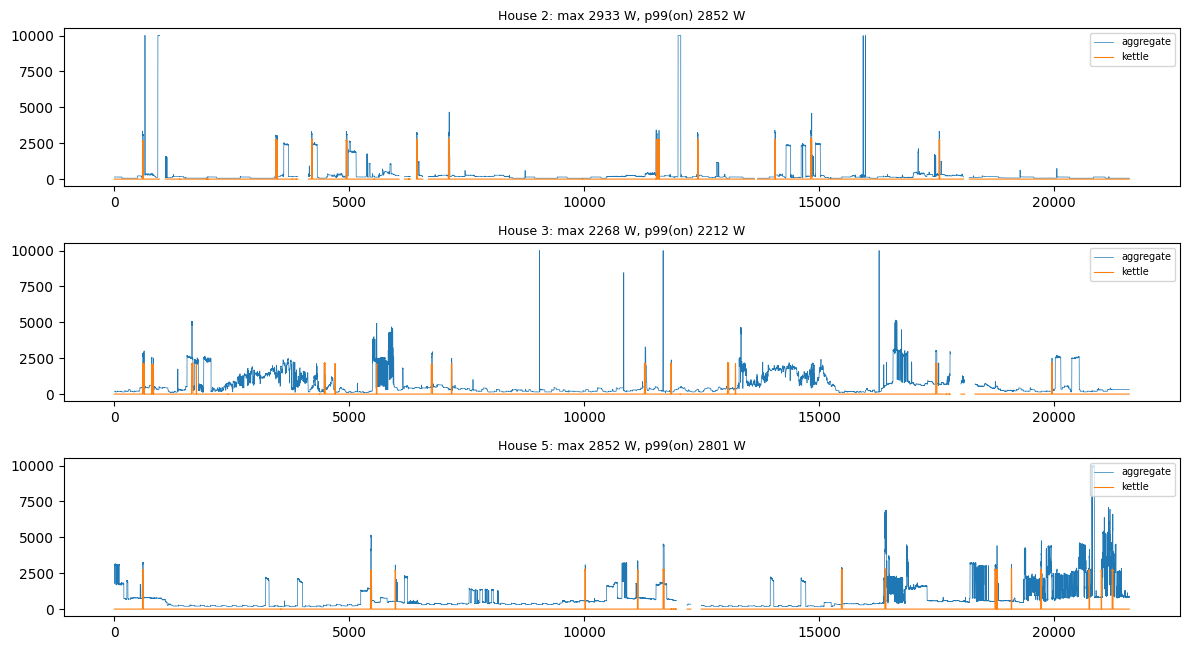

  ▶ seq2point | P0_random | test house pooled | seed 0 | train 2,601,626 val 325,203 test 325,204
    ep 1/5 loss 0.8768 | val MAE  38.79 | test MAE  39.25 | 13s
    ep 2/5 loss 0.6472 | val MAE  34.31 | test MAE  34.49 | 10s
    ep 3/5 loss 0.4596 | val MAE  20.01 | test MAE  19.80 | 10s
    ep 4/5 loss 0.3755 | val MAE  18.25 | test MAE  18.04 | 10s
    ep 5/5 loss 0.3336 | val MAE  18.40 | test MAE  18.02 | 10s
  ▶ hi_s2p | P0_random | test house pooled | seed 0 | train 2,601,626 val 325,203 test 325,204
    ep 1/5 loss 1.1283 | val MAE  36.98 | test MAE  37.90 | 47s
    ep 2/5 loss 0.6608 | val MAE  21.72 | test MAE  21.23 | 49s
    ep 3/5 loss 0.5227 | val MAE  18.23 | test MAE  17.82 | 48s
    ep 4/5 loss 0.4580 | val MAE  16.63 | test MAE  16.18 | 48s
    ep 5/5 loss 0.4079 | val MAE  15.28 | test MAE  14.57 | 48s
  ▶ beacon | P0_random | test house pooled | seed 0 | train 2,601,626 val 325,203 test 325,204
    ep 1/5 loss 3.7809 | val MAE  15.23 | test MAE  15.59 | 21s
    ep 2

In [10]:
def per_house_rows(S, idx, y, p, base_row, variant, extra=None, mask=None):
    """Metrics per test house (pooled P0/P1 test sets are split by house to compare with P2 house by house)."""
    hs = S['house'][idx]; out = []
    for h in np.unique(hs):
        m = hs == h if mask is None else (hs == h) & mask
        if m.sum() == 0: continue
        r = dict(base_row, test_house=int(h), variant=variant, **metrics(y[m], p[m], S['on_threshold']))
        r.update(extra or {}); out.append(r)
    return out

def evaluate_variants(model, S, D, split, st, best, base_row):
    rows = []; te = split['test']; y = S['y'][te]
    def add(variant, yy, pp, extra=None, mask=None):
        if mask is not None:   # yy/pp are full arrays, mask selects points
            rows.extend(per_house_rows(S, te, yy, pp, base_row, variant, extra, mask))
        else:
            rows.extend(per_house_rows(S, te, yy, pp, base_row, variant, extra))
    model.load_state_dict(best['val'][1])
    p = predict(model, D, te, st)
    add('clean', y, p, dict(best_epoch=best['val'][2]))
    p4 = (p - p.mean()) / (p.std() + 1e-6) * y.std() + y.mean()
    add('L4_target_stats', y, np.clip(p4, 0, None))
    m = active_window_mask(S, te)
    if m.sum() > 0: add('L5_curated', y, p, mask=m)
    model.load_state_dict(best['test'][1])
    add('L6_test_selected', y, predict(model, D, te, st), dict(best_epoch=best['test'][2]))
    model.load_state_dict(best['val'][1])
    return rows, p

def run_appliance(appliance):
    print(f'\n================ {appliance.upper()} ================')
    S = build_store(appliance)
    if len(S['houses']) < 3:
        print('not enough houses for LOHO'); return None, None, None
    S['house_stats'].to_csv(os.path.join(OUT_DIR, f'house_stats_{appliance}.csv'), index=False)
    display(S['house_stats'].round(4))
    sanity_plot(S)
    D = Data(S)
    out_csv = os.path.join(OUT_DIR, f'results_{appliance}.csv')
    done = pd.read_csv(out_csv) if os.path.exists(out_csv) else pd.DataFrame()
    rows = done.to_dict('records'); keep = {}
    for seed in SEEDS:
        for split in make_splits(S, seed):
            th = split['test_house']
            base_info = dict(appliance=appliance, seed=seed, protocol=split['protocol'], split_id=str(th))
            # baselines
            def exists(mname, variant):
                return any(r.get('model') == mname and r['seed'] == seed and r['protocol'] == split['protocol']
                           and str(r.get('split_id')) == str(th) and r.get('variant') == variant for r in rows)
            if not exists('always_off', 'clean'):
                te = split['test']
                for bname, bp in baselines(S, split).items():
                    rows.extend(per_house_rows(S, te, S['y'][te], bp, dict(base_info, model=bname), 'clean'))
            for mname in MODELS:
                if mname in ABLATION_MODELS and split['protocol'] != 'P2_loho':
                    continue
                if RUN_L3_RETRAIN and mname in MAIN_MODELS and split['protocol'] == 'P2_loho' and not exists(mname, 'L3_denoised'):
                    print(f'  ▶ {mname} | P2_loho [L3 denoised train+test] | test house {th} | seed {seed}')
                    m3, st3, best3, _ = train_model(mname, S, D, split, seed, source='den')
                    m3.load_state_dict(best3['val'][1])
                    te = split['test']
                    rows.extend(per_house_rows(S, te, S['y'][te], predict(m3, D, te, st3, 'den'),
                                               dict(base_info, model=mname), 'L3_denoised',
                                               dict(best_epoch=best3['val'][2])))
                    pd.DataFrame(rows).to_csv(out_csv, index=False); del m3; torch.cuda.empty_cache()
                if exists(mname, 'clean'):
                    print(f'  skipping {mname} {split["protocol"]} house={th} seed={seed} (already done)'); continue
                print(f'  ▶ {mname} | {split["protocol"]} | test house {th} | seed {seed} | '
                      f'train {len(split["train"]):,} val {len(split["val"]):,} test {len(split["test"]):,}')
                model, st, best, hist = train_model(mname, S, D, split, seed)
                r, _ = evaluate_variants(model, S, D, split, st, best, dict(base_info, model=mname))
                rows += r
                pd.DataFrame(rows).to_csv(out_csv, index=False)
                if seed == SEEDS[0] and split['protocol'] in ('P0_random', 'P2_loho') and (mname, split['protocol']) not in keep:
                    keep[(mname, split['protocol'])] = (model, st, split)   # kept for knowledge extraction
                else:
                    del model
                torch.cuda.empty_cache()
    df = pd.DataFrame(rows); df.to_csv(out_csv, index=False)
    return df, S, (D, keep)

ALL = {}
for app in APPLIANCES:
    df, S, extra = run_appliance(app)
    if df is not None: ALL[app] = (df, S, extra)

## 9. Results: optimism gap
- **optimism_MAE_%** = (P2-clean MAE − variant MAE) / P2-clean MAE × 100 → positive = the setting makes the model look better than it is
- **ΔF1**, **Δprecision** = variant value − P2-clean value (same model) → positive = optimistic (mainly used for L5)
- All values are per-house means; P0/P1 are restricted to the P2 test houses so that comparisons are house by house.

In [11]:
def summarize(df):
    d = df.copy()
    p2_houses = set(d.loc[d.protocol == 'P2_loho', 'test_house'].astype(str))
    d = d[d.test_house.astype(str).isin(p2_houses) | d.protocol.str.startswith('P3')]   # compare on the same houses
    ref = d[(d.protocol == 'P2_loho') & (d.variant == 'clean')].groupby('model')[['MAE', 'F1', 'precision']].mean()
    g = d.groupby(['model', 'protocol', 'variant'])[['MAE', 'SAE', 'NDE', 'F1', 'precision', 'recall']].mean().reset_index()
    r = ref.reindex(g.model).reset_index(drop=True)
    g['optimism_MAE_%'] = 100 * (r['MAE'] - g['MAE']) / r['MAE']
    g['dF1'] = g['F1'] - r['F1']; g['dPrecision'] = g['precision'] - r['precision']
    return g.sort_values(['model', 'protocol', 'variant'])

MIN_HOUSES_WILCOXON = 6   # exact two-sided test: min p = 2/2**n → n = 5 gives 0.0625, n = 6 gives 0.031
MIN_HOUSES_CI = 5         # bootstrap intervals over fewer houses are not meaningful

def bootstrap_ci(x, n=2000, seed=0):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    if len(x) < MIN_HOUSES_CI: return (np.nan, np.nan)
    m = [rng.choice(x, len(x)).mean() for _ in range(n)]
    return tuple(np.percentile(m, [2.5, 97.5]))

for app, (df, S, _) in ALL.items():
    print(f'\n### {app}')
    s = summarize(df)
    display(s.round(3))
    s.to_csv(os.path.join(OUT_DIR, f'summary_{app}.csv'), index=False)
    # LOHO: mean across houses + 95% CI (house = unit of analysis; CI only with enough houses)
    loho = df[(df.protocol == 'P2_loho') & (df.variant == 'clean')]
    print('\nP2_loho (clean) — per-house MAE, mean [95% bootstrap CI across houses]')
    for m, g in loho.groupby('model'):
        per_house = g.groupby('test_house')['MAE'].mean()
        lo, hi = bootstrap_ci(per_house.values)
        print(f'  {m:<18} {per_house.mean():7.2f} W  [{lo:.2f}, {hi:.2f}]  (n houses = {len(per_house)})')


### kettle


,model,protocol,variant,MAE,SAE,NDE,F1,precision,recall,optimism_MAE_%,dF1,dPrecision
0,always_off,P0_random,clean,20.397,1.000,1.000,0.000,0.000,0.000,0.965,0.000,0.000
1,always_off,P1_chrono,clean,22.763,1.000,1.000,0.000,0.000,0.000,-10.522,0.000,0.000
2,always_off,P2_loho,clean,20.596,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
3,beacon,P0_random,L4_target_stats,13.409,0.051,0.574,0.673,0.707,0.643,8.945,0.029,0.025
4,beacon,P0_random,L5_curated,42.626,0.180,0.503,0.695,0.760,0.642,-189.454,0.050,0.078
5,beacon,P0_random,L6_test_selected,11.873,0.150,0.545,0.675,0.712,0.642,19.373,0.031,0.030
6,beacon,P0_random,clean,11.873,0.150,0.545,0.675,0.712,0.642,19.373,0.031,0.030
7,beacon,P1_chrono,L4_target_stats,23.029,0.308,0.756,0.538,0.675,0.469,-56.382,-0.106,-0.007
8,beacon,P1_chrono,L5_curated,52.449,0.462,0.633,0.550,0.757,0.467,-256.163,-0.094,0.075
9,beacon,P1_chrono,L6_test_selected,17.592,0.265,0.699,0.567,0.643,0.519,-19.464,-0.077,-0.039



P2_loho (clean) — per-house MAE, mean [95% bootstrap CI across houses]
  always_off           20.60 W  [nan, nan]  (n houses = 2)
  beacon               14.73 W  [nan, nan]  (n houses = 2)
  hi_s2p               15.81 W  [nan, nan]  (n houses = 2)
  hour_of_day_mean     42.56 W  [nan, nan]  (n houses = 2)
  seq2point            23.56 W  [nan, nan]  (n houses = 2)
  train_mean           42.39 W  [nan, nan]  (n houses = 2)


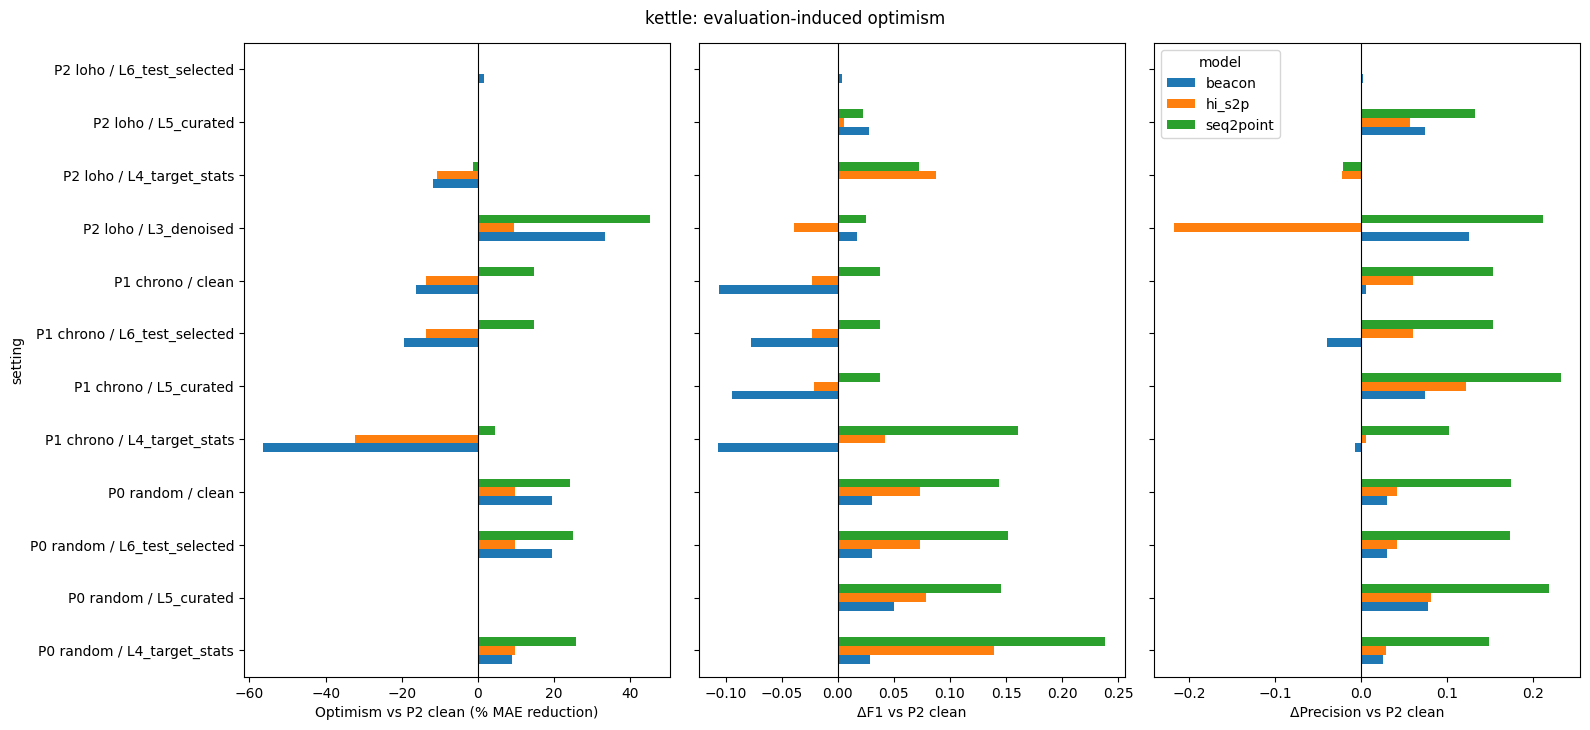

In [12]:
def plot_gap(df, app):
    s = summarize(df)
    s = s[s.model.isin(MAIN_MODELS)].copy()
    s['setting'] = s.protocol.str.replace('_', ' ') + ' / ' + s.variant
    order = [i for i in sorted(s.setting.unique()) if not ('P2' in i and i.endswith('clean'))]
    fig, axes = plt.subplots(1, 3, figsize=(16, 0.45 * len(order) + 2), sharey=True)
    for ax, col, lab in [(axes[0], 'optimism_MAE_%', 'Optimism vs P2 clean (% MAE reduction)'),
                         (axes[1], 'dF1', 'ΔF1 vs P2 clean'), (axes[2], 'dPrecision', 'ΔPrecision vs P2 clean')]:
        piv = s.pivot_table(index='setting', columns='model', values=col).reindex(order)
        if col == 'optimism_MAE_%':
            piv.loc[[i for i in order if 'L5' in i]] = np.nan      # L5 is read through F1/precision only
        piv.plot.barh(ax=ax, legend=(ax is axes[2])); ax.axvline(0, color='k', lw=.8); ax.set_xlabel(lab)
    fig.suptitle(f'{app}: evaluation-induced optimism'); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'optimism_{app}.png'), dpi=200); plt.show()

for app, (df, S, _) in ALL.items():
    plot_gap(df, app)


In [13]:
# 9.1 BEACON vs. each other model, paired per house (P2 LOHO, clean) — Wilcoxon signed-rank + bootstrap CI of the difference
from scipy.stats import wilcoxon
stat_rows = []
for app, (df, S, _) in ALL.items():
    p2 = df[(df.protocol == 'P2_loho') & (df.variant == 'clean')]
    per = p2.groupby(['model', 'test_house'])[['MAE', 'NDE', 'F1']].mean()
    if 'beacon' not in per.index.get_level_values(0): continue
    b = per.loc['beacon']
    for ref in [m for m in per.index.get_level_values(0).unique() if m != 'beacon']:
        r = per.loc[ref]; hs = b.index.intersection(r.index)
        for met in ['MAE', 'NDE', 'F1']:
            d = (b.loc[hs, met] - r.loc[hs, met]).dropna()
            pval = wilcoxon(d.values).pvalue if len(d) >= MIN_HOUSES_WILCOXON and np.any(d.values != 0) else np.nan
            lo, hi = bootstrap_ci(d.values)
            stat_rows.append(dict(appliance=app, comparison=f'beacon − {ref}', metric=met, n_houses=len(d),
                                  mean_diff=d.mean(), ci_lo=lo, ci_hi=hi, wilcoxon_p=pval,
                                  beacon_better=int(np.sum(d < 0) if met != 'F1' else np.sum(d > 0))))
stats_df = pd.DataFrame(stat_rows)
display(stats_df.round(4))
stats_df.to_csv(os.path.join(OUT_DIR, 'stats_beacon_pairwise.csv'), index=False)
print(f'Note: negative MAE/NDE or positive F1 = BEACON better; p-values need ≥ {MIN_HOUSES_WILCOXON} houses, CIs ≥ {MIN_HOUSES_CI}')


,appliance,comparison,metric,n_houses,mean_diff,ci_lo,ci_hi,wilcoxon_p,beacon_better
0,kettle,beacon − always_off,MAE,2,-5.8695,NaN,NaN,NaN,2
1,kettle,beacon − always_off,NDE,2,-0.3237,NaN,NaN,NaN,1
2,kettle,beacon − always_off,F1,2,0.6444,NaN,NaN,NaN,2
3,kettle,beacon − hi_s2p,MAE,2,-1.0827,NaN,NaN,NaN,1
4,kettle,beacon − hi_s2p,NDE,2,0.2148,NaN,NaN,NaN,0
5,kettle,beacon − hi_s2p,F1,2,0.1234,NaN,NaN,NaN,2
6,kettle,beacon − hour_of_day_mean,MAE,2,-27.8303,NaN,NaN,NaN,2
7,kettle,beacon − hour_of_day_mean,NDE,2,-0.3151,NaN,NaN,NaN,1
8,kettle,beacon − hour_of_day_mean,F1,2,0.6444,NaN,NaN,NaN,2
9,kettle,beacon − seq2point,MAE,2,-8.8350,NaN,NaN,NaN,2


Note: negative MAE/NDE or positive F1 = BEACON better; p-values need ≥ 6 houses, CIs ≥ 5


## 10. Knowledge extraction — what do the models learn?
1. **Baseline-shift sensitivity**: add a constant +100 W to the whole window (mimicking a house with a higher standby load) and measure how much the prediction changes; a sensitive model uses the house's load level as a shortcut. HI-S2P and BEACON use shift-invariant inputs; for BEACON the value can be non-zero because of the aggregate constraint ŷ ≤ x, a physical bound rather than a shortcut — interpret it together with the house probe.
2. **House-identity probe**: a logistic regression on the model's head features (windows from up to 6 houses) predicts which house a window came from; higher accuracy = features encode house identity more strongly (chance = 1/number of houses).
3. **Occlusion saliency**: occlude one segment of the window at a time and measure the change in prediction (for BEACON, the soft ungated output), comparing models trained under P0 and P2.

,appliance,model,protocol,shift_sensitivity_W,house_probe_acc,chance
0,kettle,seq2point,P0_random,0.468,0.510,0.333
1,kettle,hi_s2p,P0_random,0.000,0.660,0.333
2,kettle,beacon,P0_random,0.055,0.628,0.333
3,kettle,seq2point,P2_loho,1.032,0.599,0.333
4,kettle,hi_s2p,P2_loho,0.000,0.643,0.333
5,kettle,beacon,P2_loho,0.162,0.709,0.333


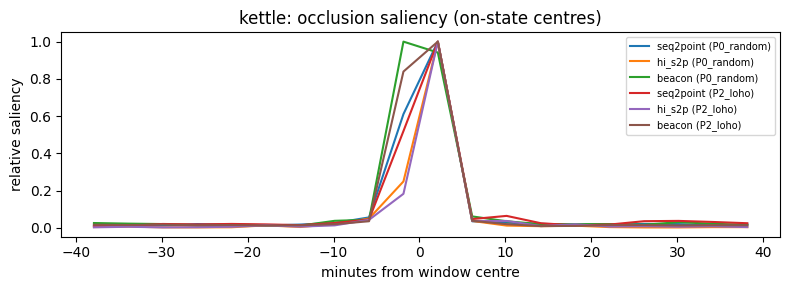

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

@torch.no_grad()
def get_features(model, D, idx, st, bs=2048):
    model.eval(); fs = []
    for i in range(0, len(idx), bs):
        c = torch.as_tensor(idx[i:i + bs], device=DEVICE)
        x = (D.windows(c) - st['x_mean']) / st['x_std']
        fs.append(model.features(x).float().cpu().numpy())
    return np.concatenate(fs)

@torch.no_grad()
def occlusion_profile(model, D, idx, st, seg=30):
    model.eval(); c = torch.as_tensor(idx, device=DEVICE)
    x = (D.windows(c) - st['x_mean']) / st['x_std']
    base = model(x)['power']; prof = []
    for s0 in range(0, WINDOW, seg):
        xo = x.clone(); xo[:, s0:s0 + seg] = x.median(dim=1, keepdim=True).values
        prof.append((model(xo)['power'] - base).abs().mean().item())
    return np.array(prof)

ke_rows = []
for app, (df, S, (D, keep)) in ALL.items():
    rng = np.random.default_rng(0)
    for (mname, proto), (model, st, split) in keep.items():
        te = split['test']; sample = te[rng.integers(0, len(te), min(20_000, len(te)))]
        p0 = predict(model, D, sample, st); p1 = predict(model, D, sample, st, shift_w=100.0)
        # probe on random windows from each house
        hs = S['houses'][:6]
        pidx = np.concatenate([rng.choice(S['centers'][h], 1500) for h in hs])
        if len(hs) < 2: continue
        feats = get_features(model, D, pidx, st); lab = S['house'][pidx]
        cv = StratifiedKFold(3, shuffle=True, random_state=0)
        acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                              feats, lab, cv=cv).mean()
        ke_rows.append(dict(appliance=app, model=mname, protocol=proto,
                            shift_sensitivity_W=float(np.mean(np.abs(p1 - p0))),
                            house_probe_acc=float(acc), chance=1 / len(hs)))
    ke = pd.DataFrame(ke_rows)
    display(ke.round(3))
    ke.to_csv(os.path.join(OUT_DIR, f'knowledge_{app}.csv'), index=False)
    # occlusion: only windows whose centre is in the on state
    fig, ax = plt.subplots(figsize=(8, 3))
    for (mname, proto), (model, st, split) in keep.items():
        te = split['test']; act = te[S['y'][te] > S['on_threshold']]
        if len(act) == 0: continue
        prof = occlusion_profile(model, D, act[rng.integers(0, len(act), min(2000, len(act)))], st)
        xs = (np.arange(len(prof)) * 30 + 15 - WINDOW // 2) * SAMPLE_PERIOD / 60
        ax.plot(xs, prof / (prof.max() + 1e-9), label=f'{mname} ({proto})')
    ax.set_xlabel('minutes from window centre'); ax.set_ylabel('relative saliency'); ax.legend(fontsize=7)
    ax.set_title(f'{app}: occlusion saliency (on-state centres)'); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'saliency_{app}.png'), dpi=200); plt.show()

## 11. Part B (optional): Cross-dataset REFIT → UK-DALE
Uses `ukdale.h5` from Zenodo record 13917372 (Shi, 2024; CC BY 4.0; 3.3 GB).
⚠️ The file has not yet been confirmed to follow the NILMTK layout — the first cell prints its structure; if it is not `/building{b}/elec/meter{m}`, adapt `load_nilmtk_meter`.
The UK-DALE meters in `UKDALE_METERS` follow commonly used configurations; confirm them against UK-DALE's `labels.dat`.

In [15]:
RUN_CROSS_DATASET = False
UKDALE_URL = 'https://zenodo.org/records/13917372/files/ukdale.h5?download=1'
UKDALE_PATH = '/content/ukdale.h5' if IN_COLAB else 'ukdale.h5'
UKDALE_METERS = {'kettle': {1: 10, 2: 8}, 'microwave': {1: 13, 2: 15}, 'fridge': {1: 12, 2: 14},
                 'dishwasher': {1: 6, 2: 13}, 'washingmachine': {1: 5, 2: 12}}

def load_nilmtk_meter(path, building, meter, max_rows=None):
    s = pd.read_hdf(path, f'/building{building}/elec/meter{meter}', stop=max_rows)
    s = s.iloc[:, 0] if isinstance(s, pd.DataFrame) else s
    return s.resample(f'{SAMPLE_PERIOD}s').mean().ffill(limit=3)

if RUN_CROSS_DATASET:
    if not os.path.exists(UKDALE_PATH):
        subprocess.run(['wget', '-q', '--show-progress', '-O', UKDALE_PATH, UKDALE_URL], check=True)
    with pd.HDFStore(UKDALE_PATH, 'r') as store:
        keys = store.keys(); print(len(keys), 'keys, e.g.:', keys[:15])
    for app, (df, S, (D, keep)) in ALL.items():
        if app not in UKDALE_METERS: continue
        for mname in MODELS:
            if (mname, 'P2_loho') not in keep: continue
            model, st, _ = keep[(mname, 'P2_loho')]
            for b, m in UKDALE_METERS[app].items():
                try:
                    agg = load_nilmtk_meter(UKDALE_PATH, b, 1); y = load_nilmtk_meter(UKDALE_PATH, b, m)
                    j = pd.concat([agg, y], axis=1, join='inner').dropna()
                    j = j.iloc[:int(EVAL_MAX_POINTS * 2)]
                    a = np.clip(j.iloc[:, 0].values.astype(np.float32), 0, AGG_CLIP)
                    yy = np.clip(j.iloc[:, 1].values.astype(np.float32), 0, S['max_power'])
                    off = np.arange(-(WINDOW // 2), WINDOW // 2 + 1)
                    cidx = np.arange(WINDOW // 2, len(a) - WINDOW // 2, 2)
                    preds = []
                    with torch.no_grad():
                        model.eval(); At = torch.tensor(a, device=DEVICE)
                        for i in range(0, len(cidx), 4096):
                            c = torch.as_tensor(cidx[i:i + 4096], device=DEVICE)
                            xr = At[c.unsqueeze(1) + torch.as_tensor(off, device=DEVICE)]
                            preds.append(model_power_w(model, xr, st).cpu().numpy())
                    r = dict(appliance=app, model=mname, protocol='P3_cross_UKDALE', test_house=f'ukdale_b{b}',
                             variant='clean', seed=SEEDS[0], **metrics(yy[cidx], np.concatenate(preds), S['on_threshold']))
                    print(r); df.loc[len(df)] = r
                except Exception as e:
                    print(f'  UK-DALE b{b} m{m}: {e}')
        df.to_csv(os.path.join(OUT_DIR, f'results_{app}.csv'), index=False)

## 12. Export
Files in `OUT_DIR`: `results_*.csv` (raw per-run results), `summary_*.csv`, `knowledge_*.csv`, `house_stats_*.csv`, `stats_beacon_pairwise.csv` and the `.png` figures.

In [16]:
import shutil
zip_path = shutil.make_archive(os.path.join(os.path.dirname(OUT_DIR), 'nilm_results'), 'zip', OUT_DIR)
print('saved:', zip_path)
if IN_COLAB and not SAVE_TO_DRIVE:
    from google.colab import files
    files.download(zip_path)

saved: /content/nilm_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>